<a href="https://colab.research.google.com/github/huynhtamtri2006-gif/TH---MACHINE_LEARNING/blob/main/tuan_2/B%C3%80I_T%E1%BA%ACP_4_BU%E1%BB%94I_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Khai báo thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
#Tải và khám phá dữ liệu
boston = fetch_openml(
    name='boston',
    version=1,
    as_frame=True
)

X = boston.data.astype(float)
y = boston.target.astype(float)

df = X.copy()
df['MEDV'] = y

print("Kích thước dữ liệu:", df.shape)
print("Số lượng đặc trưng:", X.shape[1])
print("Số lượng mẫu:", X.shape[0])

display(df.head(10))

print("\nKiểm tra dữ liệu thiếu:")
print(df.isnull().sum())

display(df.describe())

Kích thước dữ liệu: (506, 14)
Số lượng đặc trưng: 13
Số lượng mẫu: 506


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2
5,0.02985,0.0,2.18,0.0,0.458,6.430,58.7,6.0622,3.0,222.0,18.7,394.12,5.21,28.7
6,0.08829,12.5,7.87,0.0,0.524,6.012,66.6,5.5605,5.0,311.0,15.2,395.60,12.43,22.9
7,0.14455,12.5,7.87,0.0,0.524,6.172,96.1,5.9505,5.0,311.0,15.2,396.90,19.15,27.1
8,0.21124,12.5,7.87,0.0,0.524,5.631,100.0,6.0821,5.0,311.0,15.2,386.63,29.93,16.5
9,0.17004,12.5,7.87,0.0,0.524,6.004,85.9,6.5921,5.0,311.0,15.2,386.71,17.10,18.9



Kiểm tra dữ liệu thiếu:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [3]:
#Phân chia tập huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (404, 13)
X_test: (102, 13)
y_train: (404,)
y_test: (102,)


In [4]:
#Chuẩn hóa dữ liệu
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Dữ liệu trước chuẩn hóa:")
display(X_train.head())

print("\nDữ liệu sau chuẩn hóa:")
display(pd.DataFrame(
    X_train_scaled,
    columns=X.columns
).head())

print("\nMean:")
print(X_train_scaled.mean(axis=0))

print("\nStandard Deviation:")
print(X_train_scaled.std(axis=0))

Dữ liệu trước chuẩn hóa:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
477,15.02340,0.0,18.10,0.0,0.6140,5.304,97.3,2.1007,24.0,666.0,20.2,349.48,24.91
15,0.62739,0.0,8.14,0.0,0.5380,5.834,56.5,4.4986,4.0,307.0,21.0,395.62,8.47
332,0.03466,35.0,6.06,0.0,0.4379,6.031,23.3,6.6407,1.0,304.0,16.9,362.25,7.83
423,7.05042,0.0,18.10,0.0,0.6140,6.103,85.1,2.0218,24.0,666.0,20.2,2.52,23.29
19,0.72580,0.0,8.14,0.0,0.5380,5.727,69.5,3.7965,4.0,307.0,21.0,390.95,11.28



Dữ liệu sau chuẩn hóa:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,1.287702,-0.500320,1.033237,-0.278089,0.489252,-1.428069,1.028015,-0.802173,1.706891,1.578434,0.845343,-0.074337,1.753505
1,-0.336384,-0.500320,-0.413160,-0.278089,-0.157233,-0.680087,-0.431199,0.324349,-0.624360,-0.584648,1.204741,0.430184,-0.561474
2,-0.403253,1.013271,-0.715218,-0.278089,-1.008723,-0.402063,-1.618599,1.330697,-0.974048,-0.602724,-0.637176,0.065297,-0.651595
3,0.388230,-0.500320,1.033237,-0.278089,0.489252,-0.300450,0.591681,-0.839240,1.706891,1.578434,0.845343,-3.868193,1.525387
4,-0.325282,-0.500320,-0.413160,-0.278089,-0.157233,-0.831094,0.033747,-0.005494,-0.624360,-0.584648,1.204741,0.379119,-0.165787



Mean:
[-2.63815372e-17  0.00000000e+00 -4.17707673e-17  1.31907686e-17
 -5.11142284e-16 -2.61616911e-16 -4.85859977e-16  5.24882668e-17
 -9.45338417e-17 -1.51693839e-16  8.51903806e-16 -4.94653823e-16
 -1.79174607e-16]

Standard Deviation:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [5]:
#Xây dựng mô hình SVR với Linear Kernel
svr_linear = SVR(
    kernel='linear',
    C=1.0,
    epsilon=0.1
)

svr_linear.fit(X_train_scaled, y_train)

y_pred_linear = svr_linear.predict(X_test_scaled)

mse_linear = mean_squared_error(
    y_test, y_pred_linear
)

r2_linear = r2_score(
    y_test, y_pred_linear
)

print("SVR Linear Kernel")

print(f"MSE: {mse_linear:.4f}")
print(f"R2 Score: {r2_linear:.4f}")


SVR Linear Kernel
MSE: 28.9185
R2 Score: 0.6057


In [6]:
#Xây dựng mô hình SVR với RBF Kernel
svr_rbf = SVR(
    kernel='rbf',
    C=1.0,
    epsilon=0.1,
    gamma='scale'
)

svr_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = svr_rbf.predict(X_test_scaled)

mse_rbf = mean_squared_error(
    y_test, y_pred_rbf
)

r2_rbf = r2_score(
    y_test, y_pred_rbf
)

print("SVR RBF Kernel")

print(f"MSE: {mse_rbf:.4f}")
print(f"R2 Score: {r2_rbf:.4f}")

SVR RBF Kernel
MSE: 25.6685
R2 Score: 0.6500


In [7]:
#Tổng hợp kết quả hai mô hình
df_results = pd.DataFrame({
    'Model': ['SVR Linear', 'SVR RBF'],
    'MSE': [mse_linear, mse_rbf],
    'R2 Score': [r2_linear, r2_rbf]
})

display(df_results.round(4))

,Model,MSE,R2 Score
0,SVR Linear,28.9185,0.6057
1,SVR RBF,25.6685,0.6500


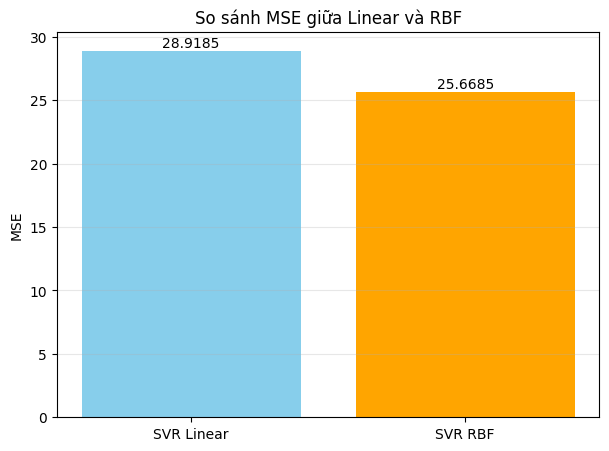

In [8]:
#Vẽ biểu đồ so sánh MSE
plt.figure(figsize=(7, 5))

bars = plt.bar(
    df_results['Model'],
    df_results['MSE'],
    color=['skyblue', 'orange']
)

plt.bar_label(bars, fmt='%.4f')

plt.ylabel('MSE')
plt.title('So sánh MSE giữa Linear và RBF')
plt.grid(axis='y', alpha=0.3)
plt.show()


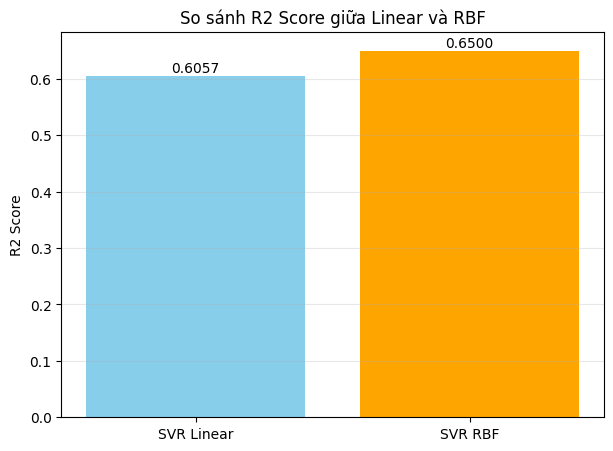

In [9]:
#Vẽ biểu đồ so sánh R² Score
plt.figure(figsize=(7, 5))

bars = plt.bar(
    df_results['Model'],
    df_results['R2 Score'],
    color=['skyblue', 'orange']
)

plt.bar_label(bars, fmt='%.4f')

plt.ylabel('R2 Score')
plt.title('So sánh R2 Score giữa Linear và RBF')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [10]:
#So sánh giá thực tế và giá dự đoán
df_predict = pd.DataFrame({
    'Actual': y_test.values,
    'Linear Prediction': y_pred_linear,
    'RBF Prediction': y_pred_rbf
})

display(df_predict.head(15))

,Actual,Linear Prediction,RBF Prediction
0,23.6,26.310163,25.956243
1,32.4,32.691705,28.045618
2,13.6,15.917779,17.736288
3,22.8,24.258893,23.124778
4,16.1,18.012776,16.461066
5,20.0,21.956363,21.296543
6,17.8,17.837157,17.330700
7,14.0,16.679859,15.829739
8,19.6,19.775680,20.004949
9,16.8,20.052981,19.271567


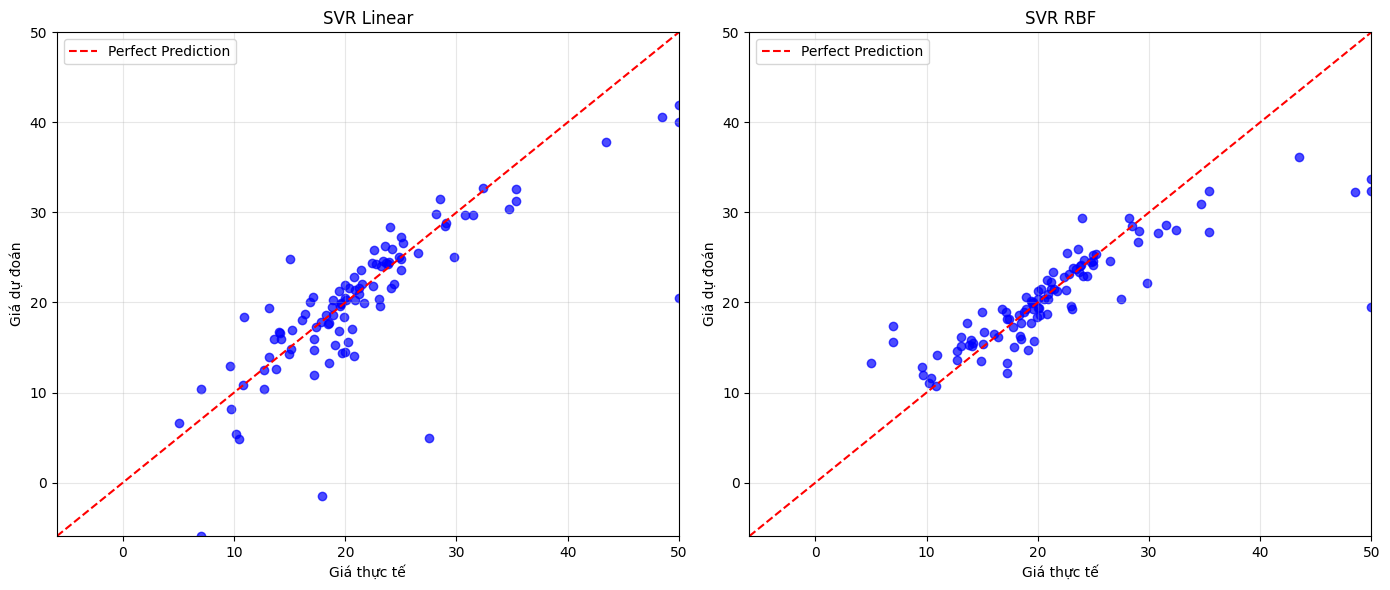

In [11]:
#Vẽ biểu đồ Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

predictions = [y_pred_linear, y_pred_rbf]
titles = ['SVR Linear', 'SVR RBF']

min_value = min(
    y_test.min(),
    y_pred_linear.min(),
    y_pred_rbf.min()
)

max_value = max(
    y_test.max(),
    y_pred_linear.max(),
    y_pred_rbf.max()
)

for ax, pred, title in zip(axes, predictions, titles):

    ax.scatter(
        y_test,
        pred,
        color='blue',
        alpha=0.7
    )

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        'r--',
        label='Perfect Prediction'
    )

    ax.set_xlabel('Giá thực tế')
    ax.set_ylabel('Giá dự đoán')
    ax.set_title(title)
    ax.set_xlim(min_value, max_value)
    ax.set_ylim(min_value, max_value)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
#Xác định mô hình tốt nhất
best_model = df_results.loc[
    df_results['MSE'].idxmin()
]

print("Mô hình tốt nhất trong thực nghiệm:")
print(best_model['Model'])

print(f"MSE: {best_model['MSE']:.4f}")
print(f"R2 Score: {best_model['R2 Score']:.4f}")

Mô hình tốt nhất trong thực nghiệm:
SVR RBF
MSE: 25.6685
R2 Score: 0.6500
